# Лабораторная работа 2. Библиотеки Data Science

## Учебная задача. Функционал библиотек машинного обучения

В учебной задаче последовательно рассматриваются библиотеки стека Python:

- **NumPy** — многомерные массивы, векторные вычисления, линейная алгебра;
- **pandas** — табличные структуры данных и подготовка выборки;
- **SciPy** — научные вычисления, статистика, оптимизация;
- **scikit-learn** — единый интерфейс моделей машинного обучения, метрики, кросс-валидация;
- **Matplotlib и Seaborn** — визуализация данных и результатов.

Для каждой библиотеки приведён небольшой пример, показывающий её основные возможности.

In [1]:
import sys

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Python:", sys.version.split()[0])
for library in (np, pd, scipy, sklearn, matplotlib, sns):
    print(f"{library.__name__}: {library.__version__}")

Python: 3.12.8
numpy: 2.4.0
pandas: 2.3.3
scipy: 1.16.3
sklearn: 1.8.0
matplotlib: 3.10.8
seaborn: 0.13.2


### NumPy

In [2]:
matrix = np.arange(1, 13).reshape(3, 4)
print(matrix)
print("shape:", matrix.shape, "| dtype:", matrix.dtype)
print("сумма по столбцам:", matrix.sum(axis=0))
print("среднее значение:", round(matrix.mean(), 3))
print("\nпроизведение матрицы на транспонированную:")
print(matrix @ matrix.T)
print("собственные числа:", np.linalg.eigvalsh(matrix @ matrix.T).round(3))

rng = np.random.default_rng(17)
sample = rng.normal(loc=10, scale=2, size=10_000)
print("\n10000 случайных значений: среднее", round(sample.mean(), 3),
      "| стандартное отклонение", round(sample.std(), 3))
print("квантили 5/50/95%:", np.quantile(sample, [0.05, 0.5, 0.95]).round(3))
print("доля значений больше 12:", round((sample > 12).mean(), 3))

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
shape: (3, 4) | dtype: int64
сумма по столбцам: [15 18 21 24]
среднее значение: 6.5

произведение матрицы на транспонированную:
[[ 30  70 110]
 [ 70 174 278]
 [110 278 446]]
собственные числа: [  0.      2.967 647.033]

10000 случайных значений: среднее 10.015 | стандартное отклонение 1.998
квантили 5/50/95%: [ 6.747 10.03  13.303]
доля значений больше 12: 0.16


### pandas

In [3]:
sales = pd.DataFrame({
    "region": ["Север", "Юг", "Запад", "Восток", "Север", "Юг", "Запад", "Восток"],
    "product": ["A", "A", "B", "B", "B", "A", "A", "B"],
    "revenue": [120, 90, 200, 150, 170, 60, 210, 130],
    "orders": [12, 9, 20, 15, 17, 6, 21, 13],
})
print(sales)
print("\nописательные статистики:")
print(sales[["revenue", "orders"]].describe().round(2))
print("\nсумма выручки по регионам:")
print(sales.groupby("region")["revenue"].sum().sort_values(ascending=False))
print("\nдоля заказов по продуктам:")
print((sales.groupby("product")["orders"].sum() / sales["orders"].sum()).round(3))
print("\nфильтр: выручка больше 150")
print(sales.query("revenue > 150"))

   region product  revenue  orders
0   Север       A      120      12
1      Юг       A       90       9
2   Запад       B      200      20
3  Восток       B      150      15
4   Север       B      170      17
5      Юг       A       60       6
6   Запад       A      210      21
7  Восток       B      130      13

описательные статистики:
       revenue  orders
count     8.00    8.00
mean    141.25   14.12
std      51.94    5.19
min      60.00    6.00
25%     112.50   11.25
50%     140.00   14.00
75%     177.50   17.75
max     210.00   21.00

сумма выручки по регионам:
region
Запад     410
Север     290
Восток    280
Юг        150
Name: revenue, dtype: int64

доля заказов по продуктам:
product
A    0.425
B    0.575
Name: orders, dtype: float64

фильтр: выручка больше 150
  region product  revenue  orders
2  Запад       B      200      20
4  Север       B      170      17
6  Запад       A      210      21


### SciPy

In [4]:
from scipy import stats, optimize

control = rng.normal(loc=10.0, scale=2.0, size=200)
experiment = rng.normal(loc=10.6, scale=2.0, size=200)

t_stat, p_value = stats.ttest_ind(control, experiment, equal_var=False)
print("t-критерий Стьюдента: t =", round(t_stat, 3), "| p-value =", round(p_value, 4))

related = control * 2 + rng.normal(0, 1, size=200)
print("корреляция Пирсона:", round(stats.pearsonr(control, related)[0], 3))

result = optimize.minimize(lambda x: (x[0] - 3) ** 2 + (x[1] + 1) ** 2, x0=[0.0, 0.0])
print("\nминимум функции в точке:", result.x.round(3), "| значение:", round(result.fun, 6))

t-критерий Стьюдента: t = -1.522 | p-value = 0.1289
корреляция Пирсона: 0.974

минимум функции в точке: [ 3. -1.] | значение: 0.0


### scikit-learn

In [5]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
print(iris.data.head())
print("\nклассы:", [str(name) for name in iris.target_names])

X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=17, stratify=y_iris)

iris_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
iris_model.fit(X_train_iris, y_train_iris)
iris_pred = iris_model.predict(X_test_iris)

print("accuracy на отложенной выборке:", round(accuracy_score(y_test_iris, iris_pred), 4))
print(classification_report(y_test_iris, iris_pred, target_names=iris.target_names))

iris_scores = cross_val_score(iris_model, X_iris, y_iris, cv=5)
print("кросс-валидация (5 блоков):", iris_scores.round(4),
      "| среднее:", round(iris_scores.mean(), 4))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

классы: ['setosa', 'versicolor', 'virginica']
accuracy на отложенной выборке: 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.87      0.90        15
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

кросс-валидация (5 блоков): [0.9667 0.9667 0.9333 0.9333 1.    ] | среднее: 0

### Matplotlib и Seaborn

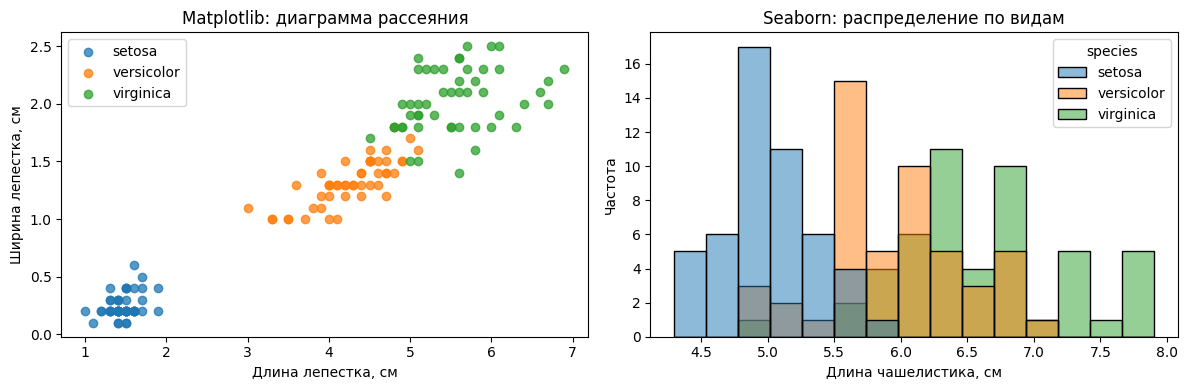

In [6]:
iris_frame = iris.frame.assign(species=iris.target_names[iris.frame["target"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for species in iris.target_names:
    subset = iris_frame[iris_frame["species"] == species]
    axes[0].scatter(subset["petal length (cm)"], subset["petal width (cm)"],
                    label=species, alpha=0.75)
axes[0].set_xlabel("Длина лепестка, см")
axes[0].set_ylabel("Ширина лепестка, см")
axes[0].set_title("Matplotlib: диаграмма рассеяния")
axes[0].legend()

sns.histplot(data=iris_frame, x="sepal length (cm)", hue="species",
             bins=15, alpha=0.5, ax=axes[1])
axes[1].set_xlabel("Длина чашелистика, см")
axes[1].set_ylabel("Частота")
axes[1].set_title("Seaborn: распределение по видам")

plt.tight_layout()
plt.savefig("figures/fig00_libraries_demo.png", dpi=150, bbox_inches="tight")
plt.show()

# Индивидуальное задание. Классификация действий межсетевого экрана

## 1. Описание набора данных

In [7]:
DATA_PATH = "datasets/internet_firewall/internet_firewall_data.csv"

firewall = pd.read_csv(DATA_PATH)
print("Размер набора:", firewall.shape)
firewall.head()

Размер набора: (65532, 12)


,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


In [8]:
print("Типы столбцов:")
print(firewall.dtypes)
print("\nВсего пропусков:", int(firewall.isna().sum().sum()))
print("Полных дубликатов строк:", int(firewall.duplicated().sum()))
print("\nЧисло уникальных значений по столбцам:")
print(firewall.nunique())

Типы столбцов:
Source Port              int64
Destination Port         int64
NAT Source Port          int64
NAT Destination Port     int64
Action                  object
Bytes                    int64
Bytes Sent               int64
Bytes Received           int64
Packets                  int64
Elapsed Time (sec)       int64
pkts_sent                int64
pkts_received            int64
dtype: object

Всего пропусков: 0
Полных дубликатов строк: 8362

Число уникальных значений по столбцам:
Source Port             22724
Destination Port         3273
NAT Source Port         29152
NAT Destination Port     2533
Action                      4
Bytes                   10724
Bytes Sent               6683
Bytes Received           8814
Packets                  1116
Elapsed Time (sec)        915
pkts_sent                 749
pkts_received             922
dtype: int64


## 2. Первичный анализ и визуализация

Action
allow         37640
deny          14987
drop          12851
reset-both       54
Name: count, dtype: int64

Доли классов:
Action
allow         0.5744
deny          0.2287
drop          0.1961
reset-both    0.0008
Name: count, dtype: float64


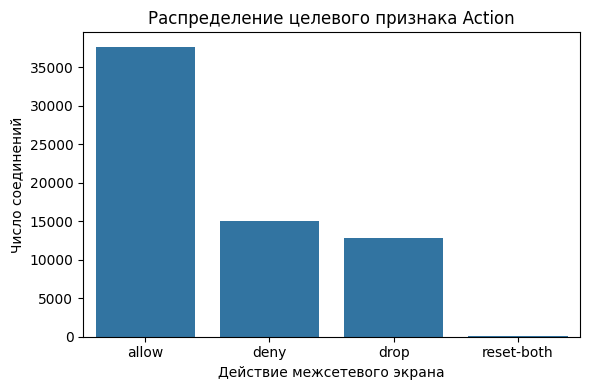

In [9]:
action_counts = firewall["Action"].value_counts()
print(action_counts)
print("\nДоли классов:")
print((action_counts / len(firewall)).round(4))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=firewall, x="Action", order=action_counts.index, ax=ax)
ax.set_title("Распределение целевого признака Action")
ax.set_xlabel("Действие межсетевого экрана")
ax.set_ylabel("Число соединений")
plt.tight_layout()
plt.savefig("figures/fig01_action_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
firewall.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Source Port,65532.0,49391.97,15255.71,0.0,49183.0,53776.5,58638.00,6.553400e+04
Destination Port,65532.0,10577.39,18466.03,0.0,80.0,445.0,15000.00,6.553500e+04
NAT Source Port,65532.0,19282.97,21970.69,0.0,0.0,8820.5,38366.25,6.553500e+04
NAT Destination Port,65532.0,2671.05,9739.16,0.0,0.0,53.0,443.00,6.553500e+04
Bytes,65532.0,97123.95,5618438.91,60.0,66.0,168.0,752.25,1.269359e+09
Bytes Sent,65532.0,22385.80,3828138.65,60.0,66.0,90.0,210.00,9.484772e+08
Bytes Received,65532.0,74738.15,2463207.71,0.0,0.0,79.0,449.00,3.208818e+08
Packets,65532.0,102.87,5133.00,1.0,1.0,2.0,6.00,1.036116e+06
Elapsed Time (sec),65532.0,65.83,302.46,0.0,0.0,15.0,30.00,1.082400e+04
pkts_sent,65532.0,41.40,3218.87,1.0,1.0,1.0,3.00,7.475200e+05


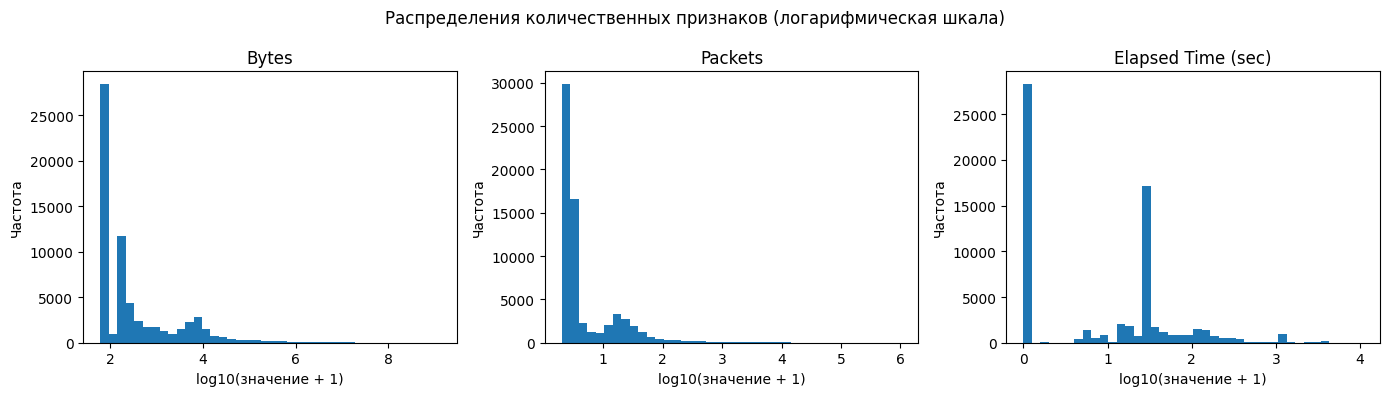

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["Bytes", "Packets", "Elapsed Time (sec)"]):
    ax.hist(np.log10(firewall[column] + 1), bins=40)
    ax.set_title(column)
    ax.set_xlabel("log10(значение + 1)")
    ax.set_ylabel("Частота")
plt.suptitle("Распределения количественных признаков (логарифмическая шкала)")
plt.tight_layout()
plt.savefig("figures/fig02_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

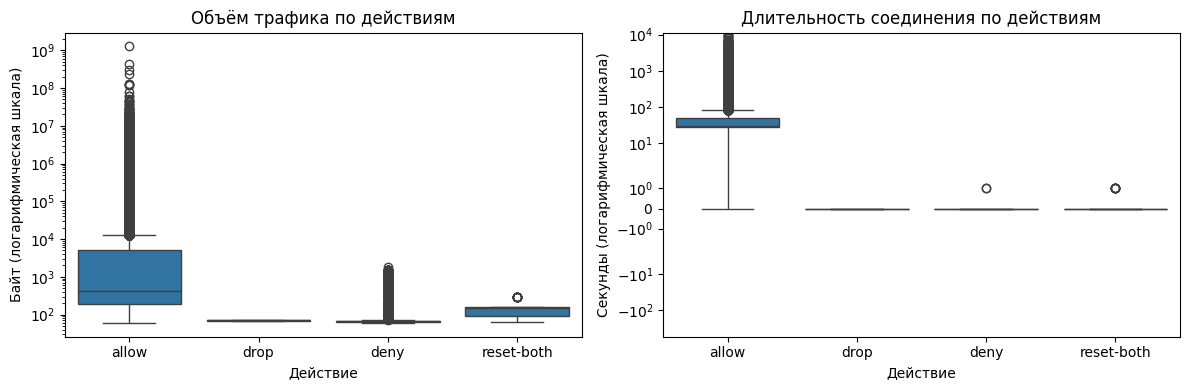

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=firewall, x="Action", y="Bytes", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Объём трафика по действиям")
axes[0].set_xlabel("Действие")
axes[0].set_ylabel("Байт (логарифмическая шкала)")

sns.boxplot(data=firewall, x="Action", y="Elapsed Time (sec)", ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_title("Длительность соединения по действиям")
axes[1].set_xlabel("Действие")
axes[1].set_ylabel("Секунды (логарифмическая шкала)")

plt.tight_layout()
plt.savefig("figures/fig03_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Action            allow  deny   drop  reset-both
Destination Port                                
53                15385    29      0           0
445                   0    40  12851           0
443               11677     7      0           0
80                 4028     7      0           0
25174                 0  1087      0           0
5900                 55   854      0           0
37965                 0   826      0           0
22114                 0   767      0           0
64147                 0   756      0           0
50584                 0   717      0           0


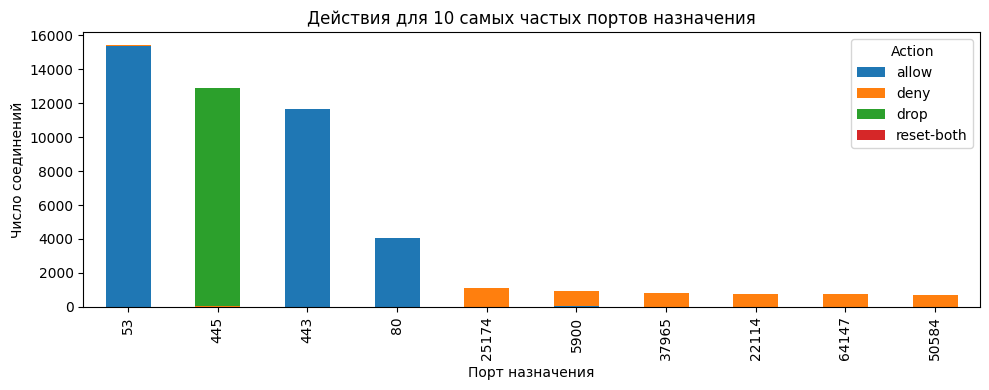

In [13]:
top_ports = firewall["Destination Port"].value_counts().head(10).index
port_action = pd.crosstab(firewall["Destination Port"], firewall["Action"]).loc[top_ports]
print(port_action)

port_action.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Действия для 10 самых частых портов назначения")
plt.xlabel("Порт назначения")
plt.ylabel("Число соединений")
plt.legend(title="Action")
plt.tight_layout()
plt.savefig("figures/fig04_top_ports.png", dpi=150, bbox_inches="tight")
plt.show()

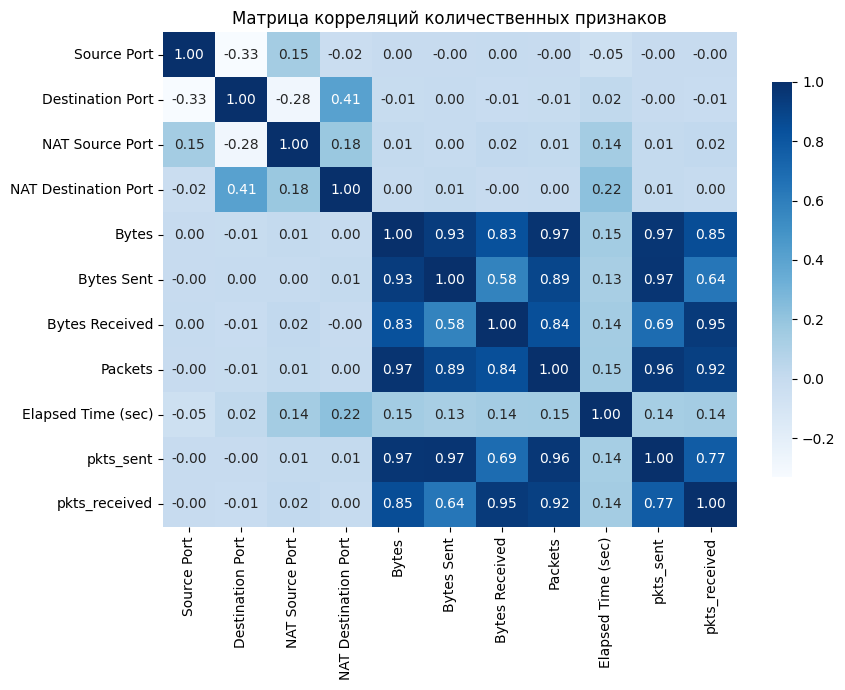

In [14]:
numeric_columns = firewall.select_dtypes("number").columns
corr = firewall[numeric_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"shrink": 0.8})
plt.title("Матрица корреляций количественных признаков")
plt.tight_layout()
plt.savefig("figures/fig05_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Предварительная обработка данных

In [15]:
data = firewall.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", data.shape)

data["Bytes per packet"] = data["Bytes"] / data["Packets"]
data["Sent share"] = data["Bytes Sent"] / data["Bytes"]
data["Packets per second"] = data["Packets"] / (data["Elapsed Time (sec)"] + 1)

features = [column for column in data.columns if column != "Action"]
X = data[features]
y = data["Action"]

print("Признаков:", len(features))
print(features)

После удаления дубликатов: (57170, 12)
Признаков: 14
['Source Port', 'Destination Port', 'NAT Source Port', 'NAT Destination Port', 'Bytes', 'Bytes Sent', 'Bytes Received', 'Packets', 'Elapsed Time (sec)', 'pkts_sent', 'pkts_received', 'Bytes per packet', 'Sent share', 'Packets per second']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=17, stratify=y)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("\nДоли классов в тестовой выборке:")
print(y_test.value_counts(normalize=True).round(4))

Обучающая выборка: (40019, 14)
Тестовая выборка: (17151, 14)

Доли классов в тестовой выборке:
Action
allow         0.6549
drop          0.2035
deny          0.1407
reset-both    0.0009
Name: proportion, dtype: float64


In [17]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

checked = ["Bytes", "Packets", "Elapsed Time (sec)"]
print("До масштабирования:")
print(X_train[checked].describe().loc[["mean", "std"]].round(2))
print("\nПосле масштабирования:")
print(pd.DataFrame(X_train_scaled, columns=features)[checked]
      .describe().loc[["mean", "std"]].round(2))

До масштабирования:
           Bytes  Packets  Elapsed Time (sec)
mean   113347.77   114.85               74.45
std   6757748.73  5616.35              315.47

После масштабирования:
      Bytes  Packets  Elapsed Time (sec)
mean    0.0      0.0                -0.0
std     1.0      1.0                 1.0


## 4. Обучение и сравнение моделей

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Логистическая регрессия": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Дерево решений": DecisionTreeClassifier(max_depth=8, random_state=17),
    "Случайный лес": RandomForestClassifier(n_estimators=200, random_state=17, n_jobs=-1),
    "Метод k ближайших соседей": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    predictions[name] = prediction
    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "F1 macro": f1_score(y_test, prediction, average="macro"),
        "F1 weighted": f1_score(y_test, prediction, average="weighted"),
    })

results = pd.DataFrame(results).set_index("Модель").round(4)
results.sort_values("F1 macro", ascending=False)

,Accuracy,F1 macro,F1 weighted
Модель,,,
Дерево решений,0.9987,0.9215,0.9987
Случайный лес,0.9981,0.8667,0.9980
Метод k ближайших соседей,0.9967,0.7464,0.9963
Логистическая регрессия,0.9889,0.7362,0.9885


In [19]:
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=3, scoring="f1_macro")
    cv_results[name] = scores.mean()
    print(f"{name}: {scores.round(4)} | среднее {scores.mean():.4f}")

Логистическая регрессия: [0.7381 0.7333 0.7337] | среднее 0.7350


Дерево решений: [0.821  0.8855 0.8767] | среднее 0.8611


Случайный лес: [0.7762 0.8651 0.8515] | среднее 0.8310


Метод k ближайших соседей: [0.7468 0.7442 0.77  ] | среднее 0.7536


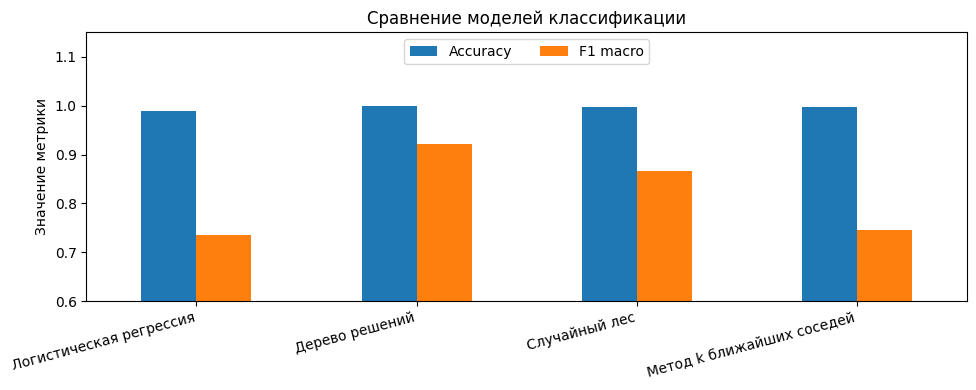

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
results[["Accuracy", "F1 macro"]].plot(kind="bar", ax=ax)
ax.set_title("Сравнение моделей классификации")
ax.set_xlabel("")
ax.set_ylabel("Значение метрики")
ax.set_ylim(0.6, 1.15)
ax.legend(loc="upper center", ncol=2)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("figures/fig06_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

Лучшая модель по macro F1: Дерево решений
              precision    recall  f1-score   support

       allow     0.9996    1.0000    0.9998     11232
        deny     0.9959    0.9950    0.9954      2413
        drop     0.9980    0.9991    0.9986      3490
  reset-both     0.9000    0.5625    0.6923        16

    accuracy                         0.9987     17151
   macro avg     0.9734    0.8892    0.9215     17151
weighted avg     0.9987    0.9987    0.9987     17151



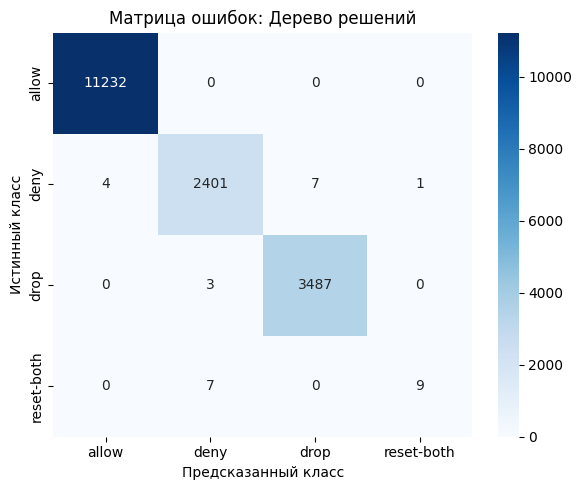

In [21]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = results["F1 macro"].idxmax()
best_model = models[best_name]
best_prediction = predictions[best_name]
print("Лучшая модель по macro F1:", best_name)
print(classification_report(y_test, best_prediction, digits=4))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_prediction, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title(f"Матрица ошибок: {best_name}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.tight_layout()
plt.savefig("figures/fig07_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pkts_sent               0.0016
Sent share              0.0291
Bytes per packet        0.0322
pkts_received           0.0326
Bytes Sent              0.0382
Packets per second      0.0431
Source Port             0.0464
Bytes Received          0.0496
Bytes                   0.0538
Packets                 0.0759
NAT Destination Port    0.1216
NAT Source Port         0.1302
Elapsed Time (sec)      0.1635
Destination Port        0.1823
dtype: float64


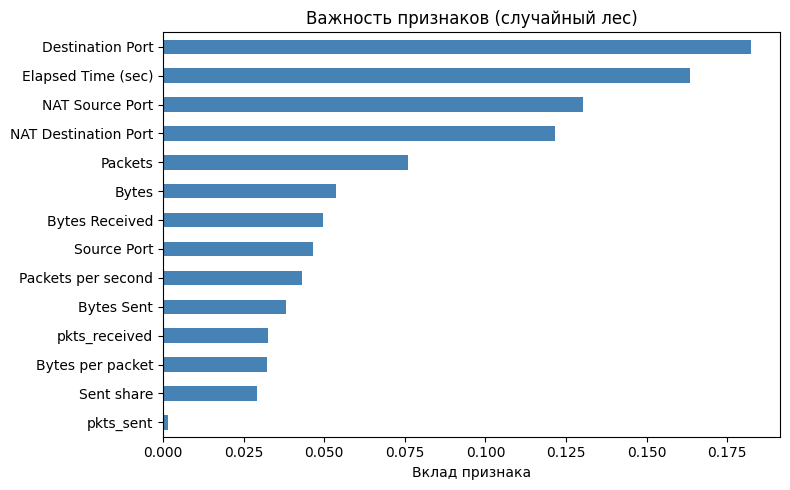

In [22]:
forest = models["Случайный лес"]
importance = pd.Series(forest.feature_importances_, index=features).sort_values()
print(importance.round(4))

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue")
plt.title("Важность признаков (случайный лес)")
plt.xlabel("Вклад признака")
plt.tight_layout()
plt.savefig("figures/fig08_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### Проверка на контрольных примерах

In [23]:
sample = X_test.sample(5, random_state=17)
check = sample[["Destination Port", "Bytes", "Packets", "Elapsed Time (sec)"]].copy()
check["Истинное действие"] = y_test.loc[sample.index]
check["Предсказание"] = best_model.predict(sample)
check

,Destination Port,Bytes,Packets,Elapsed Time (sec),Истинное действие,Предсказание
51959,80,1114,12,15,allow,allow
16162,443,530764,528,175,allow,allow
24937,443,9894856,9829,90,allow,allow
24212,443,67984,121,148,allow,allow
10680,443,6356,19,27,allow,allow
